# 공공 자전거 장기 연체 예측

<aside>
💡

이전 실습에서 정제한 데이터를 바탕으로 100분 초과 장기 연체를 예측하는 분류 모델을 만들고, 

**어떤 오류를 줄일 것인가**를 비용으로 판단합니다.

</aside>

## 배경

공공 자전거 사업자 **BikeCity** 의 운영팀에서 의뢰가 왔습니다.

> "대여 후 100분이 지나도록 반납되지 않는 장기 대여건은 자전거 방치나 연체료 미수납으로 이어지는 경우가 많습니다.
대여 시점의 정보와 과거 이용 패턴을 바탕으로 **100분 초과 연체 가능성을 조기에 예측**할 수 있을까요?"
> 

🗣️ **담당자가 덧붙인 말**

> "지난달에 데이터 분석팀이 한 번 해봤는데 **정확도가 84%** 나왔다고 하더군요.
그런데 실제로 적용하려니, 정작 연체될 자전거는 한 건도 예측하지 못했습니다. 왜 그런 걸까요?"
> 

## 이 질문에 답하는 것이 이번 과제입니다.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pprint import pprint
from _config import rentals_path, users_path, ENCODING, SEED
from _style import setup

setup()
pd.set_option("display.max_column", 20)
pd.set_option("display.width", 130)

## 데이터 준비

이번 과제에서는 **이전 데이터 파이프라인 종합실습**에서 직접 정제하여 적재한 데이터를 그대로 사용합니다. 또한, 모델링을 위해 추가로 제공된 유저 마스터 파일을 결합하여 사용합니다.

<aside>
⚠️

**이전 실습을 수행하지 않은 경우,**

이 문제는 데이터 파이프라인 실습과 이어집니다. 아직 이전 실습을 완료하지 않았다면, 먼저 데이터 정제를 수행하여 `clean_rentals.csv` 데이터를 확보한 후 진행해주세요!
종합 실습 문제  *(데이터 분석 파트 - 종합 실습 문제)*

</aside>

| 파일 | 행 수 | 내용 |
| --- | --- | --- |
| `clean_rentals.csv` | 약 13,500 | (이전 실습 최종 결과물) 정제된 대여 기록 |
| `users.csv` | 10,000 | 이용자 마스터 |

<aside>
💡

**`clean_rentals.csv` 준비 방법**

이전 실습에서 DB에 적재한 `rental_log` 데이터를 CSV로 추출하거나, 당시 작성했던 파이프라인 코드의 최종 데이터프레임을 CSV로 저장하여 사용하세요.

</aside>

### `users.csv` 컬럼 정보

- `user_id` 이용자 ID
- `join_date` 가입일
- `membership_type` 멤버십 등급 (예: 일반, 프리미엄)

## [STEP 1] 파생변수 생성 및 정답지(Target) 만들기

### 요구사항

`clean_rentals.csv`를 불러온 뒤 아래 파생변수들을 만드세요.

1. **대여 시간(분)**: `duration_min = return_time - rent_time` 의 분 단위 계산
2. **`is_overdue_100m` (예측 대상)**: 대여 시간(`duration_min`)이 100분(1시간 40분)을 초과하면 `1`, 아니면 `0`
3. 대여 시점(`rent_time`) 기준 **시간대(hour)** 와 **요일** 추출
- 전체 행 수와 **`is_overdue_100m` 의 비율**을 확인하세요.
- **"전부 정상(미반납 아님)"이라고 답할 때의 정확도**를 계산하세요. 담당자가 말한 "정확도 84%"의 정체가 바로 이것입니다.

In [2]:
rentals = pd.read_csv(rentals_path(), encoding=ENCODING,
                        parse_dates=["rent_time", "return_time"])
users = pd.read_csv(users_path(), encoding=ENCODING,
                        parse_dates=["join_date"])

# --------------------------------------
# 피처 생성
# --------------------------------------
FEATURES = [
    "duration_min",     # 대여시간(분). 이미 rentals에 있지만 만일을 위해.
    "is_overdue_100m",  # 예측 대상. 100분 초과 시 1, 100분 이하는 0.
    "rent_time_hour",   # 대여시각 기준 시간대
    "rent_dayofweek",   # 대여시각 기준 요일
]

def add_features(df:pd.DataFrame=rentals):
    """
        피처를 생성하여 반환
        - 예측 대상: 대여시간(분)의 100분 초과(연체) 여부

        Return
            df(피처가 추가된 데이터셋)
    """
    rentals = df.sort_values(["rental_id", "user_id"]).copy()

    # 날짜 타입으로 변환
    rentals["rent_time"] = pd.to_datetime(df["rent_time"])
    rentals["return_time"] = pd.to_datetime(df["return_time"])

    # duration_min
    rentals["duration_min"] = (rentals["return_time"] - rentals["rent_time"]).dt.total_seconds() / 60

    # is_overdue_100m
    rentals["is_overdue_100m"] = np.where(rentals["duration_min"] > 100, 1, 0)

    # rent_time_hour
    rentals["rent_time_hour"] = rentals["rent_time"].dt.hour

    # rent_dayofweek
    rentals["rent_dayofweek"] = rentals["rent_time"].dt.dayofweek
    
    return rentals

rentals = add_features()

# 전체 행 수와 is_overdue_100m 비율 확인
row_count = len(rentals)
overdue_count = (rentals["is_overdue_100m"] == 1).sum()
print(f"전체 행 수 {row_count:,}건")
print(f"is_overdue_100m == 1: {overdue_count:,}건")
print(f"비율(%): {(overdue_count * 100) / row_count:.2f}%")

전체 행 수 13,212건
is_overdue_100m == 1: 2,315건
비율(%): 17.52%


## [STEP 2] 결합 및 사용자 파생변수

### 요구사항

- 대여 기록에 `users.csv` 를 결합하세요. (`how` 와 `validate` 명시)
- **결합 전후 행 수를 비교**하여 중복이 발생하지 않았는지 확인하세요.
- `join_date` 와 `rent_time` 을 활용해, 대여 시점 기준 **유저의 가입 기간(일)** 파생변수를 만드세요.

In [3]:
def load_merged(rentals:pd.DataFrame, users:pd.DataFrame):
    """clean_rentals, users를 결합하여 반환"""
    rentals = add_features(rentals)

    merged = (rentals.merge(users, how="left", 
                        on="user_id", validate="many_to_one"))

    merged["join_duration"] = (merged["rent_time"] - merged["join_date"]).dt.days

    return merged.sort_values(["rental_id", "user_id"]).reset_index(drop=True)

before_merge = len(rentals)
merged = load_merged(rentals, users)
after_merge = len(merged)
print(f"before_merge == after_merge: {before_merge == after_merge}")

merged[["join_duration"]].head()
# 음수로 확인되는 값이 많은데 비회원 이용이 가능한지?
# 비회원 이용을 먼저 해본 후 회원가입 진행
#   & 비회원 이용자에게도 임시 user_id가 부여되는 경우
#   => 음수도 가능.

before_merge == after_merge: True


,join_duration
0,-314
1,-220
2,559
3,-490
4,-124


## [STEP 3] 데이터 누수 탐지

**이 단계가 이 문제의 첫 번째 관문입니다.**

지금 데이터프레임 안에는 **모델에 넣으면 안 되는 컬럼**이 섞여 있습니다.
학습 시점(대여 시점)에는 절대 알 수 없는 정보, 즉 **결과가 나온 뒤(반납 시점)에야 확정되는 값**들입니다.

### 요구사항

1. 각 컬럼들을 살펴보고 `is_overdue_100m` 와 직결되어 있는 누수(Leakage) 컬럼을 모두 찾아내세요.
2. 의심스러운 컬럼들을 찾고, **왜 학습에 쓰면 안 되는지** 설명하세요.

<aside>
💡

**판단 기준**

“이 값은 **언제** 확정되는가?”를 기준으로 판단해보세요.

우리는 사용자가 자전거를 **빌려가는 순간(`rent_time`)**에 미반납 여부를 예측해야 합니다. 그 시점에 알 수 없는 값(ex. 주행 거리)이 포함되어 있다면 모두 누수로 판단하면 됩니다.

</aside>

**리포트에 반드시 쓸 것**

- 제거한 컬럼 이름들 (최소 3개 이상)
- 그 값이 **언제** 확정되는지
- 그대로 학습하면 실제 운영에서 무슨 일이 벌어지는지

In [ ]:
pprint(merged.columns)
# 누수 컬럼: distance_km, return_time, is_overdue_100m, duration_min,
#   후불제인 경우 fee와 payment_method까지인데, 담당자의 말에 의하면
#   장기 대여건이 '연체료 미수납'으로 이어진다고 했으니 최소한 연체료는 후불이다.
#   공유 자전거 중 하나인 따릉이도 이용권 선불, 연체료 후불
#   => 연체료가 포함된 컬럼 fee와 연체료 결제수단이 포함된 payment_method도 삭제.
print()

unleaked = merged.copy()
target = unleaked[["is_overdue_100m"]].copy()

# 모델 학습에 불필요한 ID, 시간, 누수 컬럼 싹 다 드롭 리스트에 추가
dropped_cols = [
    "rental_id", "bike_id", "user_id", "return_time", 
    "is_overdue_100m", "duration_min", "fee", "payment_method",
    "station_id", "station_name"
]

unleaked = (unleaked.drop(columns=[
                col for col in dropped_cols if col in unleaked.columns],
                errors="ignore"))

pprint(unleaked.columns)

Index(['rental_id', 'bike_id', 'user_id', 'rent_time', 'return_time', 'distance_km', 'fee', 'payment_method', 'station_id',
       'bike_type', 'gear_count', 'manufacture_year', 'daily_fee', 'station_name', 'district', 'duration_min', 'is_overdue_100m',
       'rent_time_hour', 'rent_dayofweek', 'join_date', 'membership_type', 'join_duration'],
      dtype='str')

Index(['rent_time', 'distance_km', 'bike_type', 'gear_count', 'manufacture_year', 'daily_fee', 'district', 'rent_time_hour',
       'rent_dayofweek', 'join_date', 'membership_type', 'join_duration'],
      dtype='str')


## STEP 4 학습, 테스트 분할

### 요구사항

- **시점(`rent_time`) 기준**으로 분할하세요. 상위 80% 날짜를 기준선으로 삼습니다.
- 범주형 변수(`payment_method`, `membership_type` 등)를 인코딩하세요.
- **테스트 세트의 열 구성을 학습 세트에 맞추세요.**

<aside>
⚠️

**랜덤 분할을 쓰면 안 됩니다.**

시계열 데이터에서 랜덤 분할을 쓰면, 미래의 패턴으로 과거를 예측하는 오류를 범하게 됩니다.

</aside>

In [5]:
from sklearn.preprocessing import OrdinalEncoder

unleaked["is_overdue_100m"] = target

def time_split(df:pd.DataFrame, test_size=0.2):
    """학습용/테스트용 데이터를 분리, 인코딩"""
    cutoff = df["rent_time"].quantile(1 - test_size)
    train = df[df["rent_time"] <= cutoff]
    test = df[df["rent_time"] > cutoff]

    # 명목척도 -> OneHot
    # : payment_method, district
    ONEHOT_COLS = ["payment_method", "district"]
    existing_onehot_cols = [col for col in ONEHOT_COLS if col in train.columns]
    train = pd.get_dummies(train, columns=existing_onehot_cols, drop_first=True)
    test = pd.get_dummies(test, columns=existing_onehot_cols, drop_first=True)

    # 원핫인코딩으로 인해 늘어난 컬럼 개수를 .align으로 맞추기 기준: 학습용 df
    train, test = train.align(test, join="left", axis=1, fill_value=0)
    
    # 서열척도 -> Ordinal
    # : membership_type
    ordinal = OrdinalEncoder(categories=[["BASIC", "PREMIUM"]])
    train["membership_type"] = ordinal.fit_transform(train[["membership_type"]])
    test["membership_type"] = ordinal.transform(test[["membership_type"]])

    return train, test, cutoff

train, test, cutoff = time_split(unleaked)

# time_split 끝났으니까 rent_time 컬럼도 삭제하기
dropped_cols += ["rent_time"]

# 지표가 될 컬럼 (피처): train_df의 컬럼들 중 버릴 컬럼에 없는 컬럼들
FEATURES = [col for col in train.columns if col not in dropped_cols]

# 인코딩 안 된 컬럼들 해결이 안 돼서 숫자 컬럼만 걸러서 진행
# TODO
numeric_features = train[FEATURES].select_dtypes(include=[np.number, 'bool']).columns.tolist()

X_train, y_train = train[numeric_features], train["is_overdue_100m"]
X_test, y_test = test[numeric_features], test["is_overdue_100m"]

## [STEP 5] 누수의 위력 확인

STEP 3에서 찾은 컬럼 중 하나(예: `fee` 또는 `duration_min`)를 **일부러 넣어서** 학습해 보세요.

### 요구사항

`RandomForestClassifier` 로 두 번 학습하고 비교하세요.

1. 누수 컬럼을 모두 **제거한** 피처
2. 누수 컬럼을 **포함한** 피처

정확도, 재현율, F1, AUC 를 나란히 놓고 비교합니다. 누수 컬럼이 포함되었을 때 모델 성능이 비정상적으로 완벽해지는지 확인하세요.

In [6]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, recall_score, f1_score, roc_auc_score

X_tr, y_tr = X_train.copy(), train["is_overdue_100m"]
X_te, y_te = X_test.copy(), test["is_overdue_100m"]

X_tr["fee"] = merged.loc[train.index,"fee"]
X_te["fee"] = merged.loc[test.index,"fee"]

model = RandomForestClassifier(random_state=SEED)       # 정상 데이터용
m_leak = RandomForestClassifier(random_state=SEED)      # 누수 데이터용

model.fit(X_train, y_train)
pred = model.predict(X_test)
proba = model.predict_proba(X_test)[:, 1]

m_leak.fit(X_tr, y_tr)
pred_leak = m_leak.predict(X_te)
proba_leak = m_leak.predict_proba(X_te)[:, 1]

acc = accuracy_score(y_test, pred)
rec = recall_score(y_test, pred)
f1 = f1_score(y_test, pred)
auc = roc_auc_score(y_test, proba)

acc_leak = accuracy_score(y_te, pred_leak)
rec_leak = recall_score(y_te, pred_leak)
f1_leak = f1_score(y_te, pred_leak)
auc_leak = roc_auc_score(y_te, proba_leak)

print("=" * 60)
print(f"{'성능 지표':<10} | {'1. 누수 제거 (정상)':<15} | {'2. 누수 포함 (사기)':<15}")
print("-" * 60)
print(f"{'Accuracy':<10}     | {acc:.4f}              | {acc_leak:.4f}")
print(f"{'Recall':<10}     | {rec:.4f}              | {rec_leak:.4f}")
print(f"{'F1 Score':<10}     | {f1:.4f}              | {f1_leak:.4f}")
print(f"{'AUC':<10}     | {auc:.4f}              | {auc_leak:.4f}")
print("=" * 60)

성능 지표      | 1. 누수 제거 (정상)   | 2. 누수 포함 (사기)  
------------------------------------------------------------
Accuracy       | 0.8138              | 0.9697
Recall         | 0.0104              | 0.8625
F1 Score       | 0.0199              | 0.9119
AUC            | 0.4956              | 0.9965


## [STEP 6] 모델 비교

누수를 완벽히 제거한 피처(대여 시점에 알 수 있는 정보만 남김)로 여러 모델을 학습하고 비교하세요.

### 요구사항

아래 다섯 가지를 학습하고 **정확도, 정밀도, 재현율, F1, AUC** 를 표로 정리하세요.

| 모델 | 비고 |
| --- | --- |
| `DummyClassifier` | 베이스라인 |
| `LogisticRegression` | 스케일링 필요 |
| `LogisticRegression(class_weight="balanced")` | - |
| `RandomForest` | 스케일링 불필요 |
| `RandomForest(class_weight="balanced")` | - |

### 확인 문항

1. `DummyClassifier` 와 `RandomForest` 의 정확도가 거의 똑같습니다. 무슨 일이 일어난 걸까요?
2. 담당자가 말한 "정확도 84%인데 연체를 못 잡는다"가 어느 상황에 해당하나요?
3. `class_weight="balanced"` 를 넣으면 정확도가 **떨어집니다.** 그런데도 왜 불균형 데이터에서는 이 옵션을 써야 하나요?

In [7]:
import time

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# 스케일링
def with_scaler(model):
    return Pipeline([
        # 결측치 0으로 채우기
        ("imputer", SimpleImputer(strategy="constant", fill_value=0)),
        # 스케일링
        ("sc", StandardScaler()),
        ("m", model)
    ])

models = {
    "DummyClassifier": DummyClassifier(strategy="most_frequent"),
    "LogisticRegression": with_scaler(
                          LogisticRegression(max_iter=1_000, random_state=SEED)),
    "LogisticRegression(balanced)": with_scaler(
                LogisticRegression(max_iter=1_000, 
                                   random_state=SEED, class_weight="balanced")),
    "RandomForest": RandomForestClassifier(random_state=SEED),
    "RandomForest(balanced)": RandomForestClassifier(random_state=SEED, class_weight="balanced")
}

rows = []

for name, model in models.items():
    t0 = time.perf_counter()

    model.fit(X_train, y_train)
    fit_time = time.perf_counter() - 0

    pred = model.predict(X_test)

    # Dummy는 확률을 내지 못하므로 조건문으로 분기를 나눠야 함.
    if hasattr(model, "predict_proba"):
        proba = model.predict_proba(X_test)[:, 1]
    else:
        proba = [0] * len(y_test)

    rows.append({
        "model": name, "fit": model.score(X_train, y_train),
        "test(acc)": accuracy_score(y_test, pred),
        "recall": recall_score(y_test, pred),
        "f1": f1_score(y_test, pred),
        "auc": roc_auc_score(y_test, proba),
        "fit_time": fit_time
    })

result = pd.DataFrame(rows)
print(result.round(2).to_string(index=False))

# 1. `DummyClassifier` 와 `RandomForest` 의 정확도가 거의 똑같습니다. 무슨 일이 일어난 걸까요?
#    연체자보다는 제때 반납하는 이용자가 압도적으로 많다. 즉 현재 모집단의 데이터는 매우 불균형하다.
#    따라서 가장 많은 클래스인 "연체 아님(0)"으로만 찍어도 정확도가 높은데, 전부 0(음성)으로 찍기 때문에 
#    1(양성)을 단 한 건도 잡아낼 수 없다.
# 2. 담당자가 말한 "정확도 84%인데 연체를 못 잡는다"가 어느 상황에 해당하나요?
#    정확도는 높지만 재현율, 즉 실제 양성을 잡아내는 정도가 0에 수렴한다.
# 3. `class_weight="balanced"` 를 넣으면 정확도가 **떨어집니다.** 그런데도 왜 불균형 데이터에서는 이 옵션을 써야 하나요?
#    소수 클래스에 가중치를 주어 실제 상황을 좀 더 잘 재현하도록 해야 실질적으로 쓸모있는 모델이 되기 때문이다.

                       model  fit  test(acc)  recall   f1  auc  fit_time
             DummyClassifier 0.83       0.82    0.00 0.00 0.50 205351.25
          LogisticRegression 0.83       0.82    0.00 0.00 0.49 205351.31
LogisticRegression(balanced) 0.53       0.46    0.52 0.26 0.49 205351.37
                RandomForest 1.00       0.81    0.01 0.02 0.50 205352.48
      RandomForest(balanced) 1.00       0.77    0.07 0.10 0.50 205353.96


## [STEP 7] 혼동행렬과 지표

### 요구사항

`RandomForest(balanced)` 의 혼동행렬을 구하고 **TP, FN, FP, TN 을 각각 자전거 도메인 관점에서 해석**하세요.

### 확인 문항

이 문제에서 **FN(연체를 놓침) 과 FP(정상을 연체로 예측) 중 어느 쪽이 치명적인가요?** 근거와 함께 정리해주세요.

In [8]:
from sklearn.metrics import classification_report

confusion_matrix = classification_report(y_test, pred, zero_division=0)
print(confusion_matrix)

# TP: 연체자를 연체자로 판단 (정답)
# FN: 연체자를 정상 이용자로 판단 (오답)
# FP: 정상 이용자를 연체자로 판단 (오답)
# TN: 정상 이용자를 정상 이용자로 판단 (정답)

# FN보다 FP가 더 치명적이다. 연체자가 아닌데 연체자로 취급하여 비용을 청구하거나
# 경고 알림 등을 보낸다면 이용자 입장에서 불쾌감을 느낄 수 있고,
# 이는 이용자의 이탈로 이어질 수 있기 때문이다.
# (스팸 메일이 아닌데 스팸 메일로 처리하면 중요한 메일을 못 받게 될 수 있는 것과 같다고 판단)
# 청구 알림만 보내고 끝났다면 단순 CS 비용으로 처리할 수 있겠지만 만에 하나 자동 결제 시스템이
# 존재하여 정상 이용자에게서 자동으로 연체료를 출금하게 되면 법적 문제로까지 이어질 수 있고,
# 기업 이미지에도 큰 손상을 입을 수 있다.

              precision    recall  f1-score   support

           0       0.82      0.92      0.87      2163
           1       0.17      0.07      0.10       480

    accuracy                           0.77      2643
   macro avg       0.49      0.50      0.48      2643
weighted avg       0.70      0.77      0.73      2643



## [STEP 8] 비용 기반 임계값 선택

**이 단계가 이 문제의 핵심입니다.**

운영팀에서 예측 오류에 따른 비용(손실) 정보를 알려줬습니다.

| 상황 | 비용 | 설명 |
| --- | --- | --- |
| **FN** (장기 연체를 놓침) | **15,000원** | 방치 자전거 회수 인건비 및 미수납 연체료 손실 |
| **FP** (정상인데 엄한 사람 의심) | **2,000원** | 이용자에게 반납 독촉 전화/문자 발송 및 고객 불만 CS 리소스 |

### 요구사항

1. 임계값을 `0.05` 부터 `0.95` 까지 `0.05` 간격으로 바꿔가며 아래를 계산하세요.
    - TP, FN, FP, 재현율, 정밀도
    - **총비용 = FN × 15,000 + FP × 2,000**
2. **총비용이 최소가 되는 임계값**을 찾으세요.
3. 아무 예측도 하지 않았을 때(= 전부 정상 예측으로 간주하여 연체 비용을 고스란히 떠안을 때)의 비용과 비교해 **절감액**을 계산하세요.

<aside>
⚠️

**F1 최대가 정답이 아닙니다.**

비용이 비대칭적일 때는 균형(F1)이 아니라 **총비용 최소화**가 목표가 되어야 합니다.

</aside>

In [9]:
from sklearn.metrics import precision_score, confusion_matrix

ths = np.arange(0.05, 1, 0.05)

rows = []

for th in ths:
    prec = precision_score(y_test, (proba >= th).astype(int), zero_division=0)
    rec = recall_score(y_test, (proba >= th).astype(int), zero_division=0)
    # TODO confusion_matrix() 복습
    tn, fp, fn, tp = confusion_matrix(y_test, (proba >= th).astype(int)).ravel()
    total_cost = (fn * 15_000) + (fp * 2_000)
    # 아무 예측도 하지 않고 전부 정상으로 간주: TP = 0, FP =0
    # y_test에서 1(양성)의 개수 = 연체자 수 = FN = sum(y_test == 1) 
    # (y_test는 1차원 배열이나 시리즈)
    saving = sum(y_test == 1) * 15_000 - total_cost

    rows.append({
        "임계값": th, "정밀도": prec, "재현율": rec,
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "총비용": total_cost, "절감액": saving})

result = pd.DataFrame(rows)
print(result)
print()

print(f"총비용의 최솟값: {result['총비용'].min():,}")
print(f"총비용이 최소일 때 임계값: {result[result['총비용'] == result['총비용'].min()]['임계값']}")


     임계값       정밀도       재현율    TN    FP   FN   TP      총비용      절감액
0   0.05  0.181956  1.000000     5  2158    0  480  4316000  2884000
1   0.10  0.181609  0.987500    27  2136    6  474  4362000  2838000
2   0.15  0.183741  0.922917   195  1968   37  443  4491000  2709000
3   0.20  0.187299  0.847917   397  1766   73  407  4627000  2573000
4   0.25  0.182864  0.662500   742  1421  162  318  5272000  1928000
5   0.30  0.177778  0.483333  1090  1073  248  232  5866000  1334000
6   0.35  0.174224  0.304167  1471   692  334  146  6394000   806000
7   0.40  0.170034  0.210417  1670   493  379  101  6671000   529000
8   0.45  0.173669  0.129167  1868   295  418   62  6860000   340000
9   0.50  0.187215  0.085417  1985   178  439   41  6941000   259000
10  0.55  0.200000  0.052083  2063   100  455   25  7025000   175000
11  0.60  0.161765  0.022917  2106    57  469   11  7149000    51000
12  0.65  0.117647  0.008333  2133    30  476    4  7200000        0
13  0.70  0.210526  0.008333  2148

## [STEP 9] 피처 중요도와 해석

### 요구사항

- 최종 모델의 피처 중요도를 구하고 상위 5개를 막대그래프로 그리세요.
- 운영팀에 보고한다고 가정하고 **"대여 시점에 어떤 정보(요일, 시간, 가입기간 등)를 주의 깊게 모니터링해야 하는가"** 를 3줄 이내로 정리하세요.

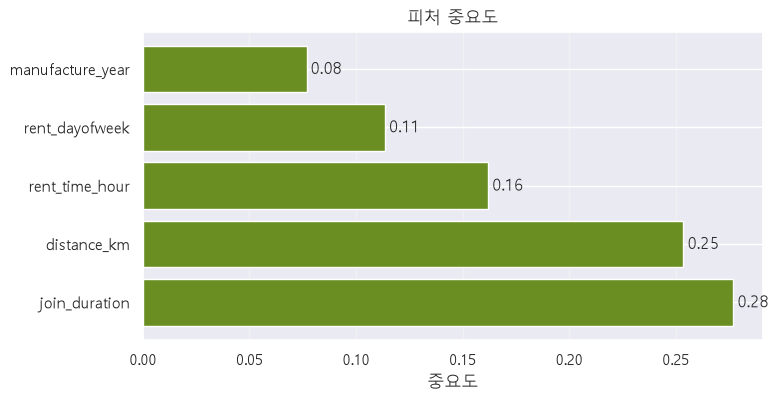

In [11]:
feat_imp = pd.Series(model.feature_importances_, 
                      index=X_train.columns).sort_values(ascending=False)
top5 = feat_imp[:5]

fig, ax = plt.subplots(figsize=(8, 4))

bars = ax.barh(top5.index, top5.to_numpy(), color="olivedrab")
ax.set_xlabel("중요도")
ax.set_title("피처 중요도")
ax.grid(alpha=0.3, axis="x")
ax.bar_label(bars, fmt="%.2f", padding=3)

plt.show()